In [7]:
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)

METHOD = "hmm_pomegranate"


In [8]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
# TARGET_PATH_TO_RESULTS = "experiment_results/"
TARGET_PATH_TO_RESULTS = "D:/Projects/MHC_predictor/trained_models/ghmm_ilya_mouse/"
#TARGET_PATH_TO_RESULTS = "D:/Projects/MHC_predictor/trained_models/ghmm_katya_mouse/models/"

In [9]:
ALLELES_KATYA= ['h2ld', 'h2kd', 'h2kb', 'h2iek', 'h2ied',
                'h2iau', 'h2ias', 'h2iaq', 'h2iak', 'h2iag7',
                'h2iad', 'h2iab', 'h2dd', 'h2db']
ALLELES_ILYA = ['h2iab', 'h2iad', 'h2iag7', 'h2iak', 'h2iaq','h2ias', 'h2iau', 'h2ied', 'h2iek' ]
ALLELES = ALLELES_ILYA

# 2. Read models

In [22]:
from hmm_logic_methods import load_model

#
#
# MOUSE_ALLELES = ['h2ld', 'h2kd', 'h2kb', 'h2iek', 'h2ied',
#                           'h2iau', 'h2ias', 'h2iaq', 'h2iak', 'h2iag7',
#                           'h2iad', 'h2iab', 'h2dd', 'h2db']

GHMM_MOUSE_MODELS= [f"{allele_name}-netmhc-binders" for allele_name in ALLELES]


per_name_model = dict()
for model_name in GHMM_MOUSE_MODELS:
    model = load_model(TARGET_PATH_TO_RESULTS, model_name)
    per_name_model[model_name] = model



# 3. Visualize
## 3.1 State graph

In [23]:
from hmm_visualization_methods import *

In [24]:
len(per_name_model)

9

In [25]:
f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph.png",

('D:/Projects/MHC_predictor/trained_models/ghmm_ilya_mouse/h2iek-netmhc-binders/state_graph.png',)

In [26]:
for model in per_name_model.values():
    with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph.png", 'w+') as f:
        model.plot(file=f, crop_zero=False)
    with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph_cropped.png", 'w+') as f:
        model.plot(file=f, crop_zero=True)

## 3.2 Distributions for states

In [27]:
%%time

for model in per_name_model.values():
    plot_distributions_for_states(model,TARGET_PATH_TO_RESULTS, horizontal=False)

Wall time: 1min 26s


## 3.3 States graph visualization (Based on previous point)

In [28]:
per_name_pyviz = dict()
for name, model in per_name_model.items():
    per_name_pyviz[name] = make_pyviz_graph(model, TARGET_PATH_TO_RESULTS, precision=3)

Converting graph for model (h2iab-netmhc-binders) (Delete zero edges)
Converting graph for model (h2iad-netmhc-binders) (Delete zero edges)
Converting graph for model (h2iag7-netmhc-binders) (Delete zero edges)
Converting graph for model (h2iak-netmhc-binders) (Delete zero edges)
Converting graph for model (h2iaq-netmhc-binders) (Delete zero edges)
Converting graph for model (h2ias-netmhc-binders) (Delete zero edges)
Converting graph for model (h2iau-netmhc-binders) (Delete zero edges)
Converting graph for model (h2ied-netmhc-binders) (Delete zero edges)
Converting graph for model (h2iek-netmhc-binders) (Delete zero edges)


## 4. Compare transition matrices

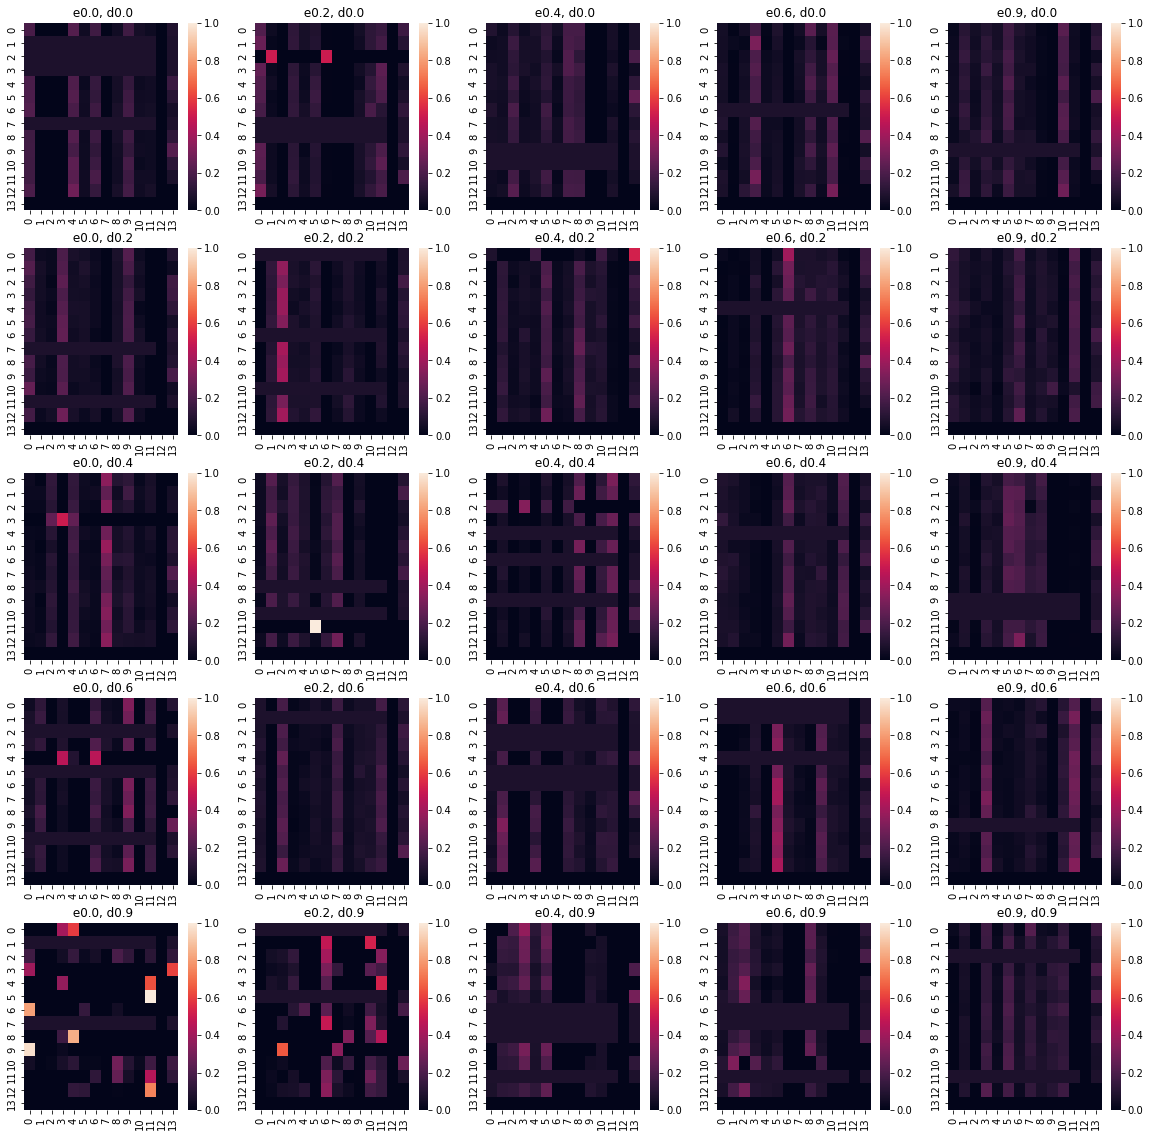

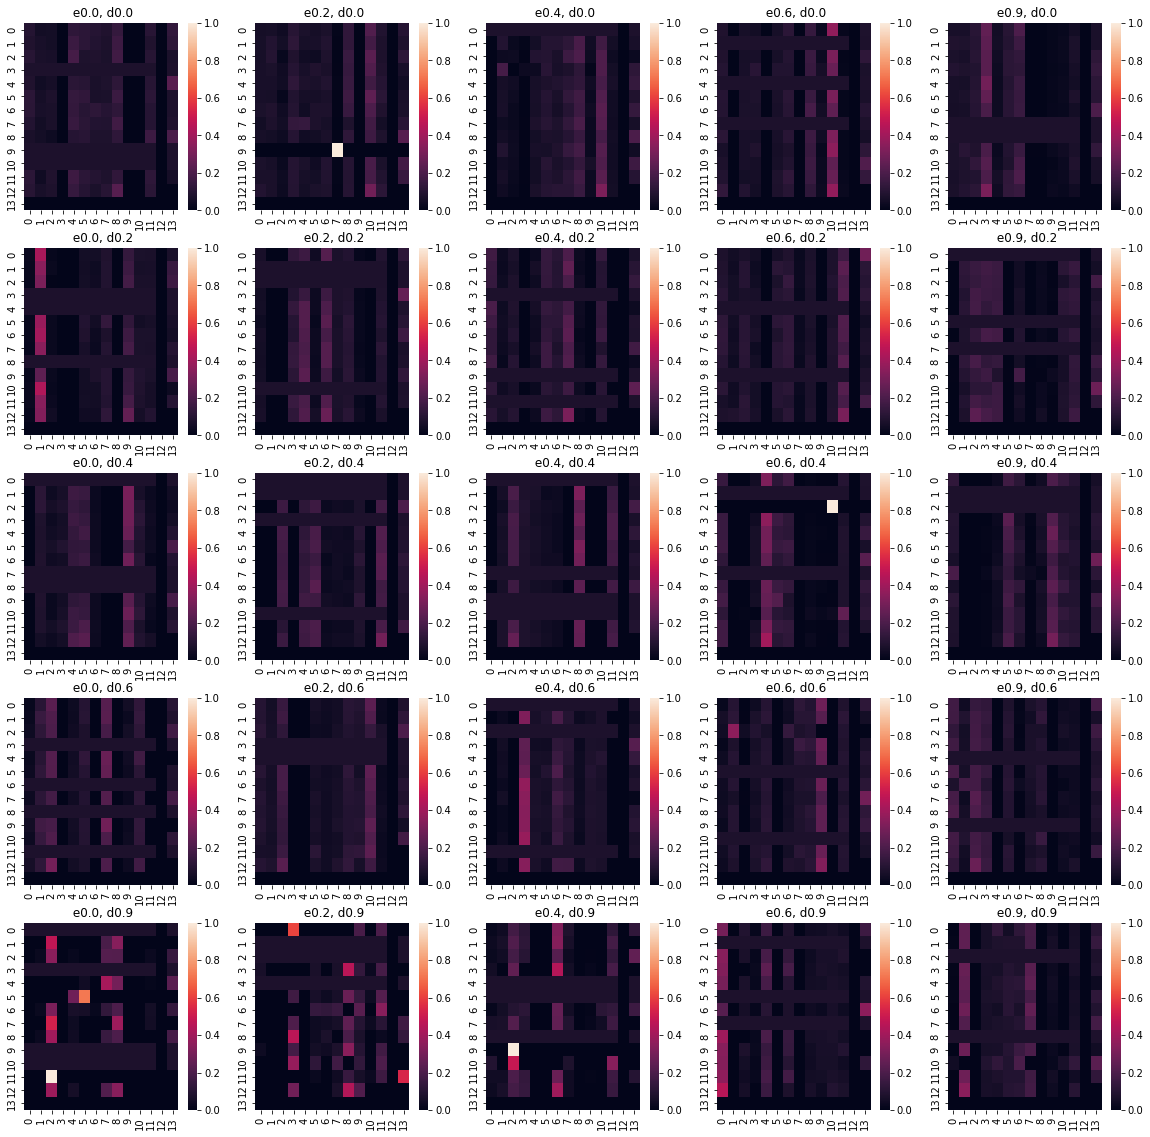

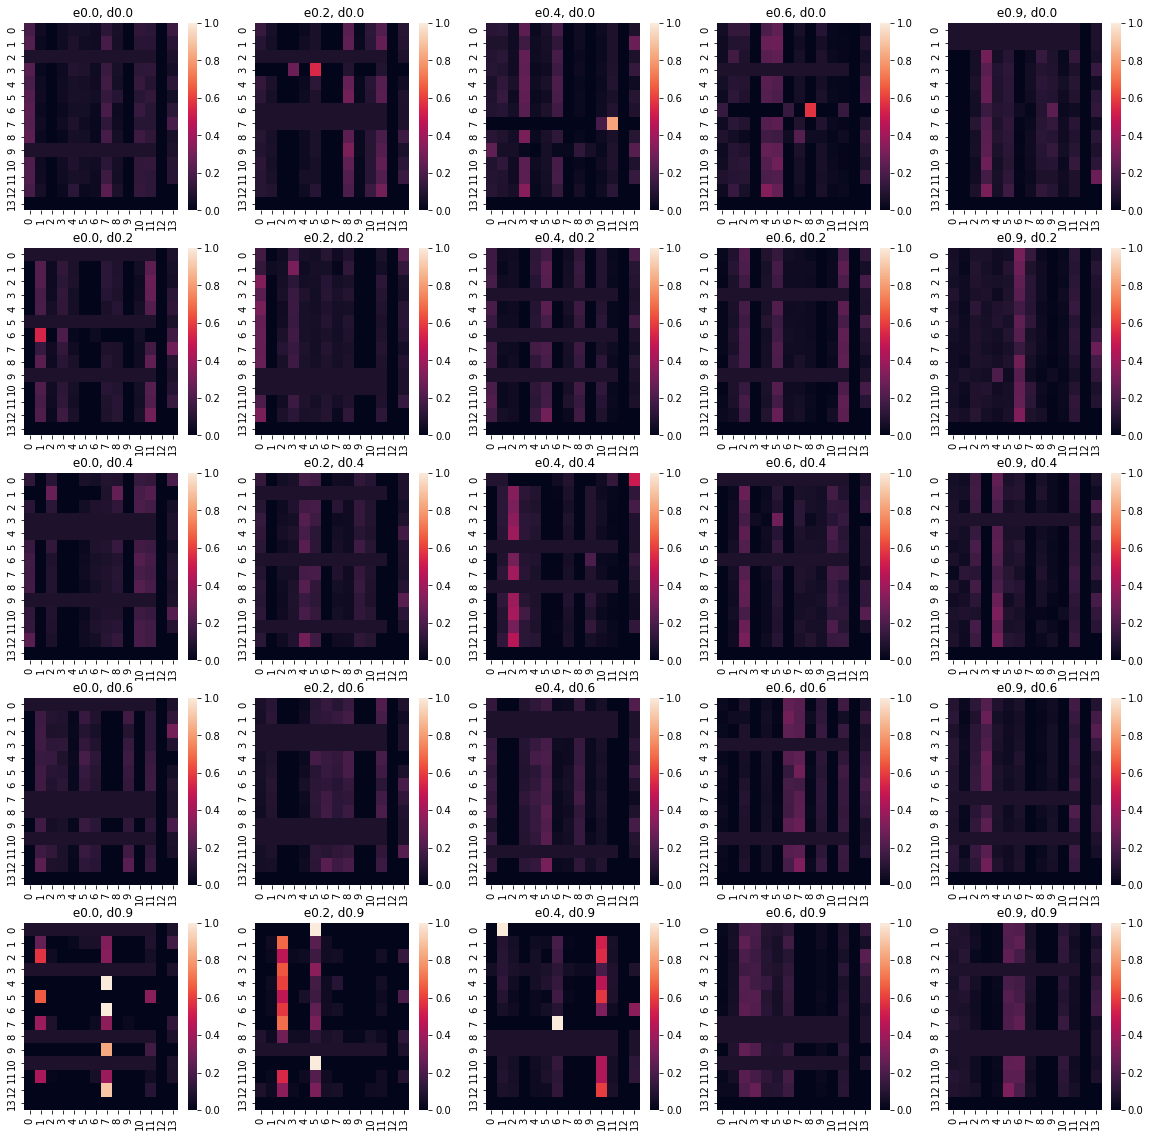

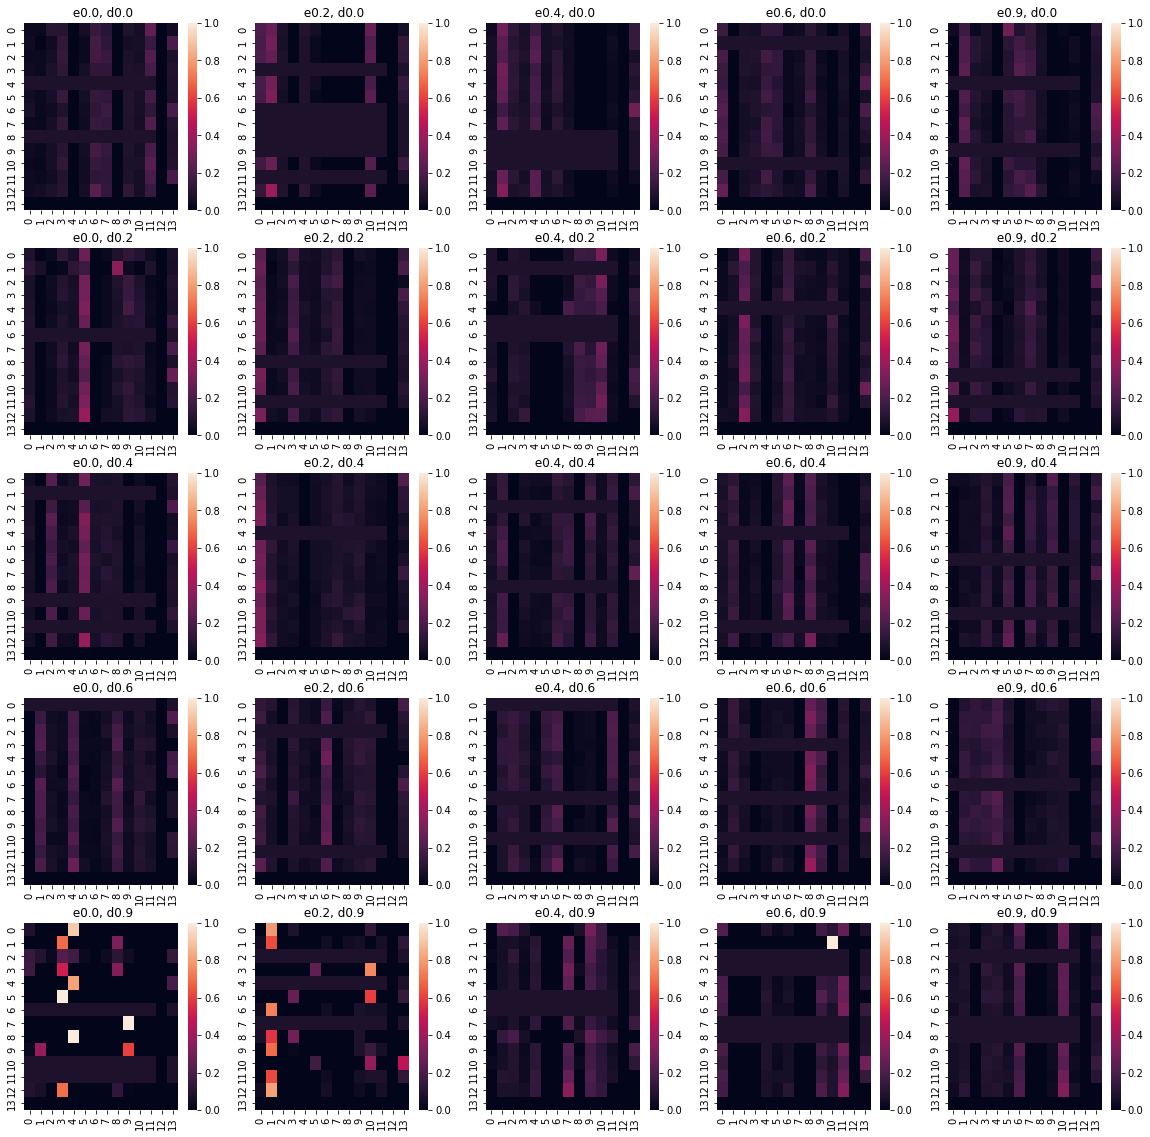

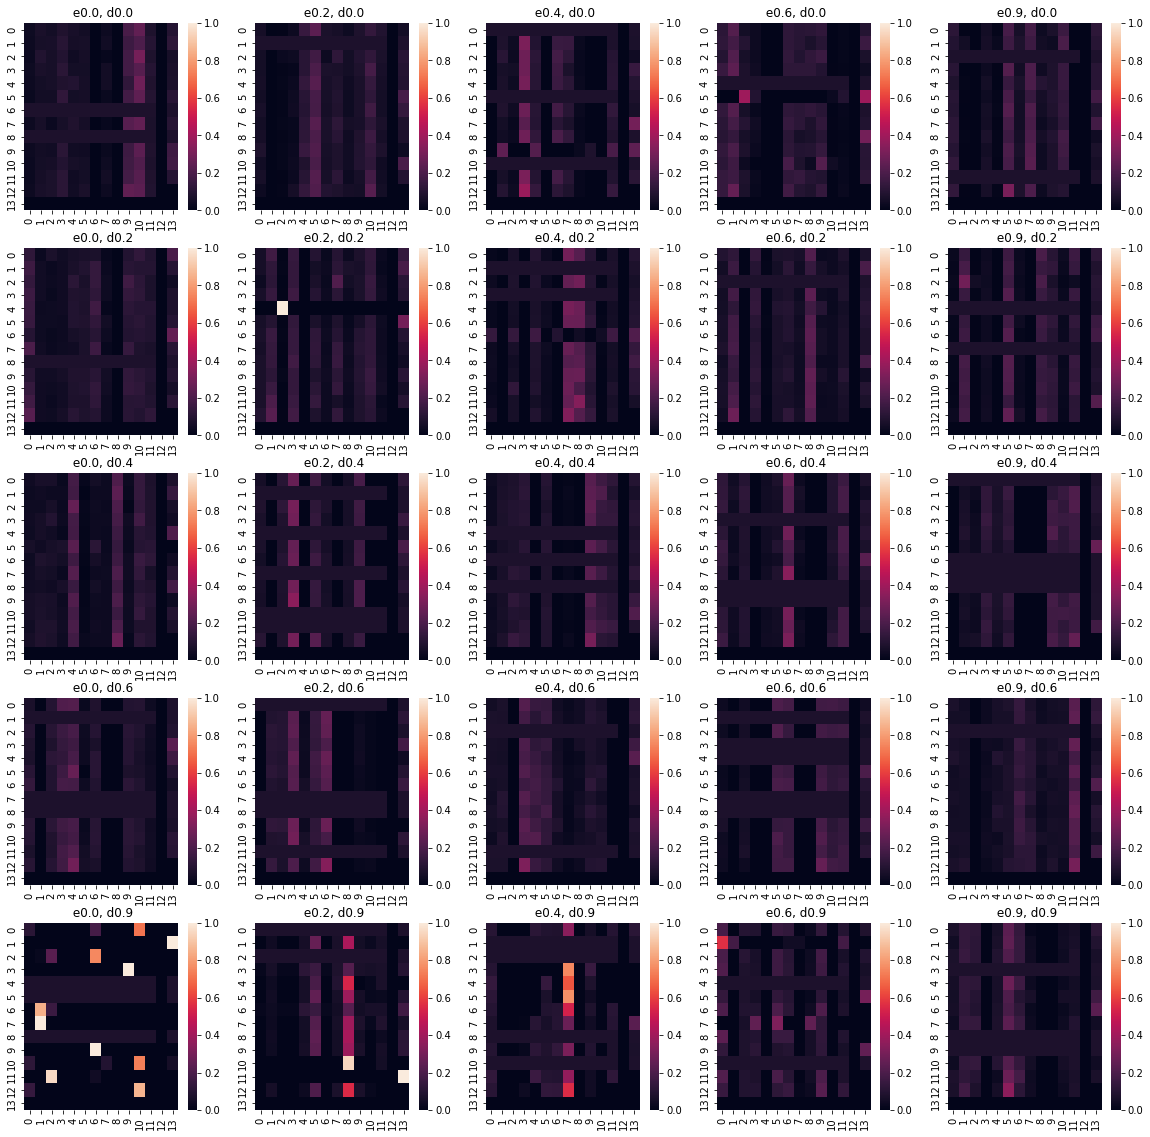

In [11]:
import seaborn as sns
edge_inertias = [0.0, 0.2, 0.4, 0.6, 0.9]
dist_inertias = [0.0, 0.2, 0.4, 0.6, 0.9]
per_comnination_model = dict()
num_splits = 5
for run in range(RUNS):
    for split in range(num_splits):
        fig, axes = plt.subplots(ncols=len(dist_inertias), nrows=len(edge_inertias),  figsize=[20, 20])
        fig.subplots_adjust(wspace=0.2, hspace=0.2)
        for i,dist_inertia in enumerate(dist_inertias):
                for j, edge_inertia in enumerate(edge_inertias):
                    name =  f'{run}_run-8-12-st-viterbi-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-{edge_inertia}-edge_inertia-{dist_inertia}-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount_model-HLA_A_02_01-{split}'
                    model = per_name_model[name]

                    ax = sns.heatmap(model.dense_transition_matrix(),vmin=0, vmax=1, ax =axes[i][j])
                    ax.set_title(f" e{edge_inertia}, d{dist_inertia}")

    break







In [13]:
model_clean = per_name_model[
    '0_run-8-12-st-viterbi-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.0-edge_inertia-0.0-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount_model-HLA_A_02_01-0']

model_dist02 = per_name_model[
    '0_run-8-12-st-viterbi-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.0-edge_inertia-0.2-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount_model-HLA_A_02_01-0']

model_dist04 = per_name_model[
    '0_run-8-12-st-viterbi-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.0-edge_inertia-0.4-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount_model-HLA_A_02_01-0']

model_dist06 = per_name_model[
    '0_run-8-12-st-viterbi-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.0-edge_inertia-0.6-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount_model-HLA_A_02_01-0']

model_dist09 = per_name_model[
    '0_run-8-12-st-viterbi-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.0-edge_inertia-0.9-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount_model-HLA_A_02_01-0']

model_both02 = per_name_model[
    '0_run-8-12-st-viterbi-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.2-edge_inertia-0.2-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount_model-HLA_A_02_01-0']

model_both04 = per_name_model[
    '0_run-8-12-st-viterbi-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.4-edge_inertia-0.4-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount_model-HLA_A_02_01-0']


model_both06 = per_name_model[
    '0_run-8-12-st-viterbi-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.6-edge_inertia-0.6-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount_model-HLA_A_02_01-0']

model_both09 = per_name_model[
    '0_run-8-12-st-viterbi-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.9-edge_inertia-0.9-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount_model-HLA_A_02_01-0']

In [14]:
model_clean.dense_transition_matrix()

array([[0.02710843, 0.0813253 , 0.0813253 , 0.04518072, 0.        ,
        0.09036145, 0.14759036, 0.        , 0.04216867, 0.15060241,
        0.03012048, 0.1626506 , 0.        , 0.14156627],
       [0.01335656, 0.06852497, 0.10511034, 0.05226481, 0.        ,
        0.09988386, 0.19860627, 0.        , 0.04006969, 0.14808362,
        0.01858304, 0.17131243, 0.        , 0.08420441],
       [0.0107896 , 0.07111329, 0.07601766, 0.07111329, 0.        ,
        0.11329083, 0.21628249, 0.        , 0.0362923 , 0.1289848 ,
        0.02108877, 0.15105444, 0.        , 0.10397254],
       [0.0190779 , 0.07551669, 0.11923688, 0.05882353, 0.        ,
        0.10413355, 0.15898251, 0.        , 0.0381558 , 0.13116057,
        0.02782194, 0.14069952, 0.        , 0.1263911 ],
       [0.07692308, 0.07692308, 0.07692308, 0.07692308, 0.07692308,
        0.07692308, 0.07692308, 0.07692308, 0.07692308, 0.07692308,
        0.07692308, 0.07692308, 0.        , 0.07692308],
       [0.01585903, 0.06696035, 0.1

In [15]:
import seaborn

ModuleNotFoundError: No module named 'seaborn'

## 3.4 Logo for sequences

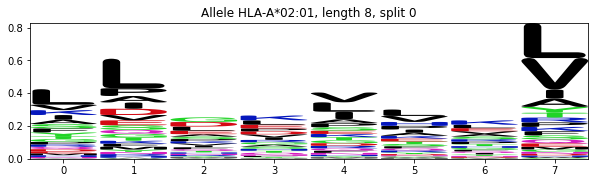

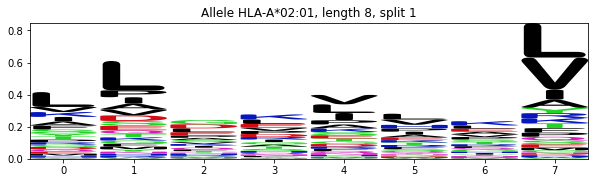

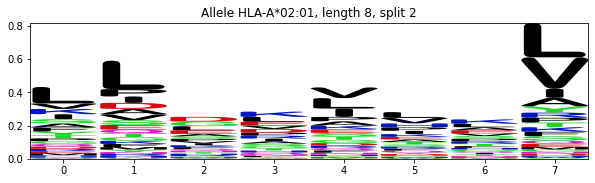

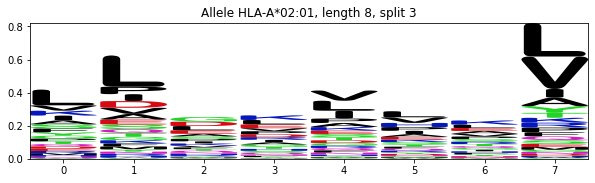

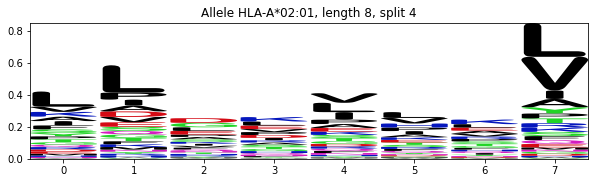

In [5]:
make_logos_for_train_sequences(8, per_allele_per_kfold_per_length_binders_train, TARGET_PATH_TO_RESULTS)